In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

campaign = pd.read_csv('../data/processed/campaign_clean.csv')
touchpoints = pd.read_csv('../data/processed/touchpoints_clean.csv')

campaign['campaign_date'] = pd.to_datetime(campaign['campaign_date'])
touchpoints['touch_time'] = pd.to_datetime(touchpoints['touch_time'])

print("Ready. Campaign:", campaign.shape, "| Touchpoints:", touchpoints.shape)

Ready. Campaign: (200000, 26) | Touchpoints: (10000, 7)


                      total_spend  total_revenue  total_conversions  avg_roi  \
channel_standardized                                                           
Social Media          827720108.0   4.971642e+09            2909276     5.00   
Email                 420874104.0   2.524644e+09            1485425     5.00   
Search Ads            418912314.0   2.516724e+09            1468717     5.00   
Display Ads           416778582.0   2.501105e+09            1463649     4.99   
Direct Traffic        416593500.0   2.504152e+09            1477660     5.01   

                      avg_ctr  
channel_standardized           
Social Media             0.14  
Email                    0.14  
Search Ads               0.14  
Display Ads              0.14  
Direct Traffic           0.14  


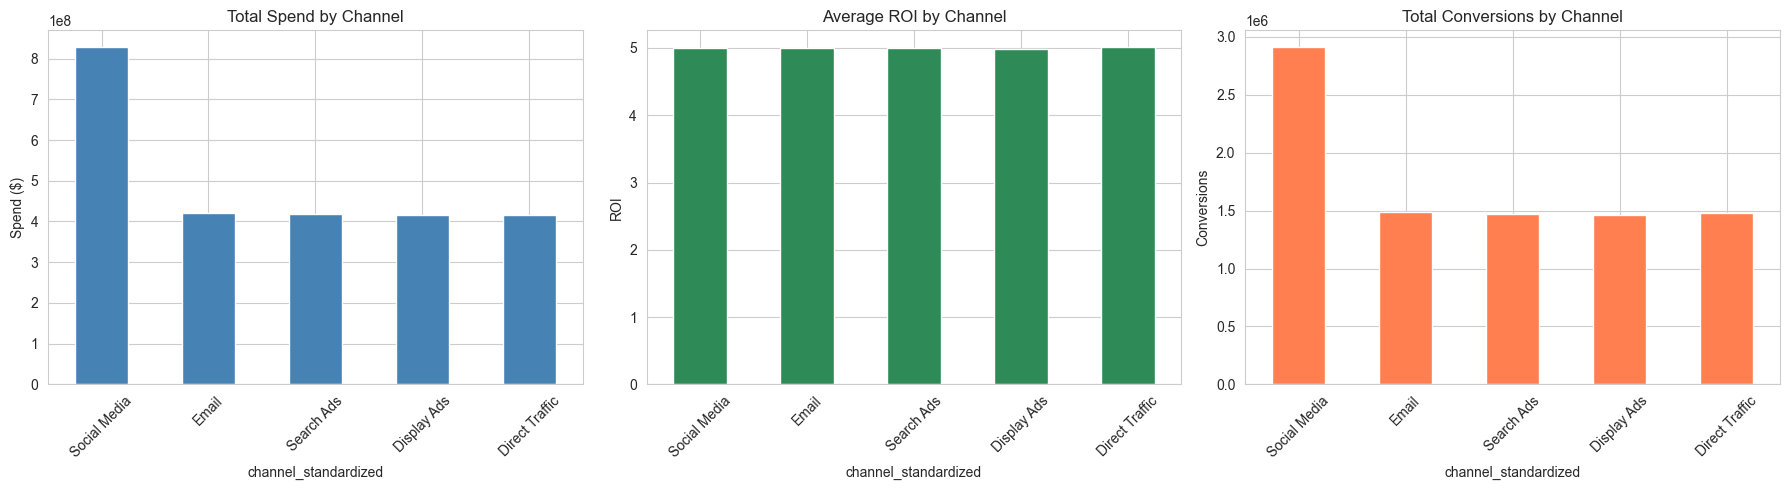

In [25]:
channel_summary = campaign.groupby('channel_standardized').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_conversions=('conversions', 'sum'),
    avg_roi=('roi', 'mean'),
    avg_ctr=('ctr', 'mean')
).round(2).sort_values('total_spend', ascending=False)

print(channel_summary)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

channel_summary['total_spend'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Total Spend by Channel')
axes[0].set_ylabel('Spend ($)')
axes[0].tick_params(axis='x', rotation=45)

channel_summary['avg_roi'].plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Average ROI by Channel')
axes[1].set_ylabel('ROI')
axes[1].tick_params(axis='x', rotation=45)

channel_summary['total_conversions'].plot(kind='bar', ax=axes[2], color='coral')
axes[2].set_title('Total Conversions by Channel')
axes[2].set_ylabel('Conversions')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../outputs/figures/channel_performance_overview.png', dpi=150, bbox_inches='tight')
plt.show()

         total_spend  total_revenue  total_conversions  avg_roi
month                                                          
2021-01  212138826.0   1.277022e+09             749513     5.01
2021-02  191464820.0   1.150137e+09             675518     5.01
2021-03  211892603.0   1.269461e+09             748406     4.98
2021-04  205452322.0   1.232186e+09             722244     4.99
2021-05  211663415.0   1.274748e+09             746884     5.02
2021-06  205516710.0   1.229120e+09             725194     4.99
2021-07  212239503.0   1.270166e+09             748763     4.98
2021-08  213545454.0   1.280370e+09             740767     5.00
2021-09  206273900.0   1.244607e+09             728936     5.03
2021-10  212709908.0   1.280674e+09             750733     5.02
2021-11  205504738.0   1.233987e+09             724398     5.00
2021-12  212476409.0   1.275788e+09             743371     5.00


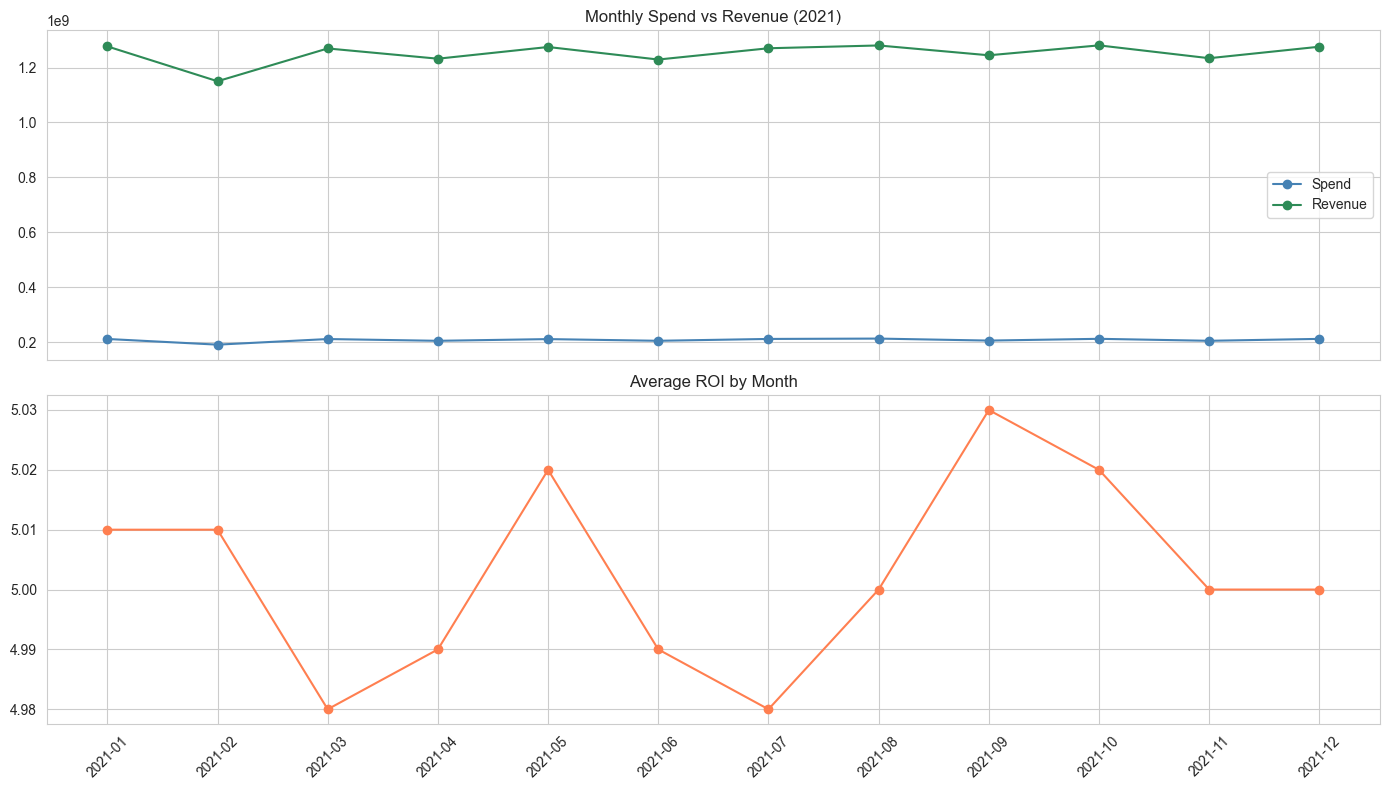

In [26]:
monthly_trend = campaign.groupby('month').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_conversions=('conversions', 'sum'),
    avg_roi=('roi', 'mean')
).round(2)

print(monthly_trend)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(monthly_trend.index, monthly_trend['total_spend'], marker='o', label='Spend', color='steelblue')
axes[0].plot(monthly_trend.index, monthly_trend['total_revenue'], marker='o', label='Revenue', color='seagreen')
axes[0].set_title('Monthly Spend vs Revenue (2021)')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(monthly_trend.index, monthly_trend['avg_roi'], marker='o', color='coral')
axes[1].set_title('Average ROI by Month')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

             total_spend  total_revenue  total_conversions  avg_roi  avg_ctr
location                                                                    
Houston      495061893.0   2.977043e+09            1749123     5.01     0.14
Miami        503974911.0   3.030077e+09            1765398     5.01     0.14
Los Angeles  500637366.0   3.010014e+09            1757555     5.01     0.14
Chicago      500731615.0   3.006315e+09            1761868     5.00     0.14
New York     500472823.0   2.994818e+09            1770783     4.98     0.14


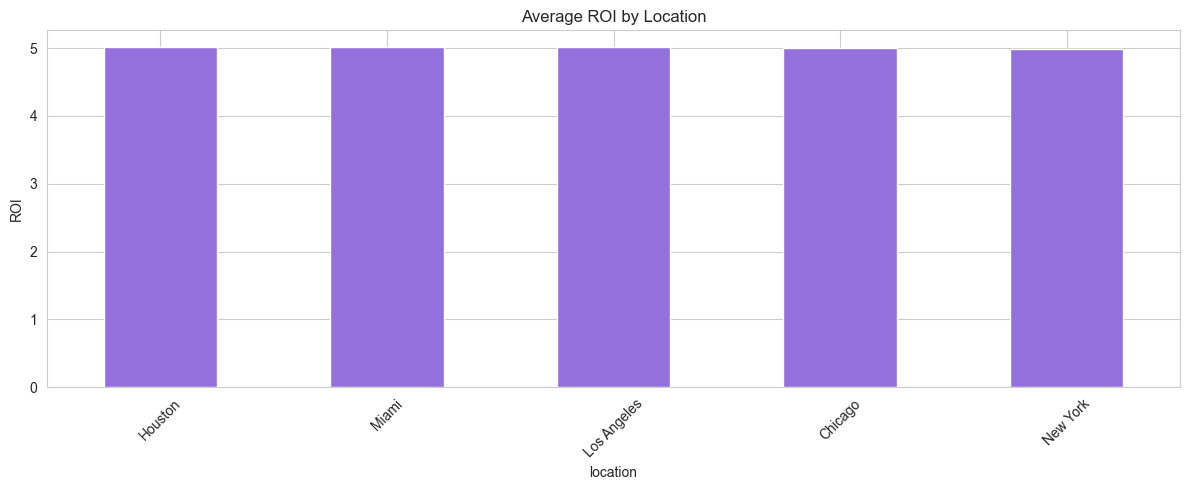

In [27]:
geo_summary = campaign.groupby('location').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_conversions=('conversions', 'sum'),
    avg_roi=('roi', 'mean'),
    avg_ctr=('ctr', 'mean')
).round(2).sort_values('avg_roi', ascending=False)

print(geo_summary)

fig, ax = plt.subplots(figsize=(12, 5))
geo_summary['avg_roi'].plot(kind='bar', ax=ax, color='mediumpurple')
ax.set_title('Average ROI by Location')
ax.set_ylabel('ROI')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

                     total_spend  total_revenue  total_conversions  avg_roi  \
customer_segment                                                              
Fashionistas         496911934.0   2.981999e+09            1744390      5.0   
Foodies              503587434.0   3.027444e+09            1774122      5.0   
Health & Wellness    498776239.0   2.995997e+09            1754209      5.0   
Outdoor Adventurers  500502742.0   3.001852e+09            1767276      5.0   
Tech Enthusiasts     501100259.0   3.010975e+09            1764730      5.0   

                     avg_engagement  
customer_segment                     
Fashionistas                   5.49  
Foodies                        5.51  
Health & Wellness              5.48  
Outdoor Adventurers            5.50  
Tech Enthusiasts               5.49  


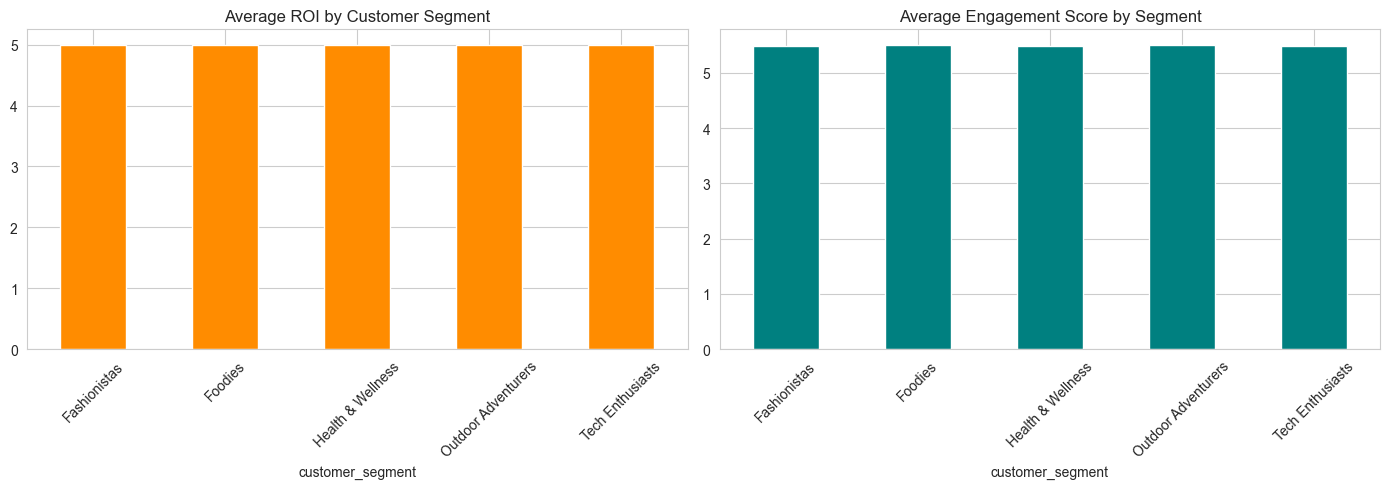

In [28]:
segment_summary = campaign.groupby('customer_segment').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_conversions=('conversions', 'sum'),
    avg_roi=('roi', 'mean'),
    avg_engagement=('engagement_score', 'mean')
).round(2).sort_values('avg_roi', ascending=False)

print(segment_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

segment_summary['avg_roi'].plot(kind='bar', ax=axes[0], color='darkorange')
axes[0].set_title('Average ROI by Customer Segment')
axes[0].tick_params(axis='x', rotation=45)

segment_summary['avg_engagement'].plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Average Engagement Score by Segment')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [29]:
# Sort by user and time first (order matters for truncation)
touchpoints_sorted = touchpoints.sort_values(['user_id', 'touch_time']).reset_index(drop=True)

def build_truncated_journey(group):
    group = group.reset_index(drop=True)
    converted_idx = group.index[group['converted'] == 1]
    if len(converted_idx) > 0:
        cutoff = converted_idx[0]  # first conversion point
        path = group.loc[:cutoff, 'channel_standardized'].tolist()
        converted = 1
    else:
        path = group['channel_standardized'].tolist()  # never converted, keep full path
        converted = 0
    return pd.Series({'path': path, 'converted': converted, 'path_length': len(path)})

journeys = (
    touchpoints_sorted
    .groupby('user_id')
    .apply(build_truncated_journey, include_groups=False)
    .reset_index()
)

print("Total customer journeys:", len(journeys))
print("Converted users:", journeys['converted'].sum())
print("Conversion rate:", round(journeys['converted'].mean() * 100, 2), "%")
print("Average touchpoints per (truncated) journey:", round(journeys['path_length'].mean(), 2))
print("\nSample journeys:")
print(journeys.head(10))

Total customer journeys: 2847
Converted users: 2381
Conversion rate: 83.63 %
Average touchpoints per (truncated) journey: 1.7

Sample journeys:
   user_id                                      path  converted  path_length
0    10028                              [Search Ads]          1            1
1    10045                 [Search Ads, Display Ads]          1            2
2    10062     [Social Media, Direct Traffic, Email]          1            3
3    10068                              [Search Ads]          1            1
4    10095                             [Display Ads]          1            1
5    10120                         [Referral, Email]          1            2
6    10167  [Social Media, Display Ads, Display Ads]          1            3
7    10172                         [Email, Referral]          1            2
8    10202             [Display Ads, Direct Traffic]          1            2
9    10255  [Social Media, Referral, Direct Traffic]          1            3


                last_touch  first_touch  linear  last_touch_pct  \
Display Ads          415.0        428.0  424.51            17.4   
Referral             412.0        408.0  409.96            17.3   
Social Media         412.0        389.0  396.84            17.3   
Direct Traffic       402.0        411.0  405.16            16.9   
Email                391.0        374.0  381.20            16.4   
Search Ads           349.0        371.0  363.33            14.7   

                first_touch_pct  linear_pct  
Display Ads                18.0        17.8  
Referral                   17.1        17.2  
Social Media               16.3        16.7  
Direct Traffic             17.3        17.0  
Email                      15.7        16.0  
Search Ads                 15.6        15.3  


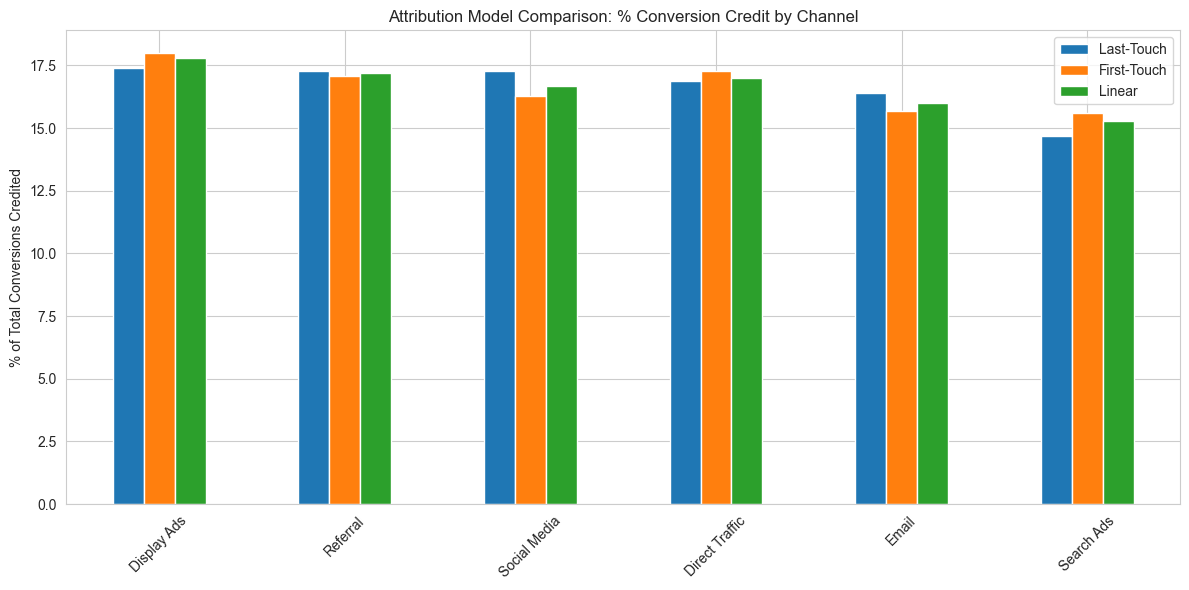

In [30]:
converted_journeys = journeys[journeys['converted'] == 1].copy()

from collections import defaultdict

last_touch_credit = defaultdict(float)
first_touch_credit = defaultdict(float)
linear_credit = defaultdict(float)

for path in converted_journeys['path']:
    last_touch_credit[path[-1]] += 1          # 100% to final channel
    first_touch_credit[path[0]] += 1          # 100% to first channel
    weight = 1 / len(path)                    # equal split across the path
    for channel in path:
        linear_credit[channel] += weight

attribution_df = pd.DataFrame({
    'last_touch': pd.Series(last_touch_credit),
    'first_touch': pd.Series(first_touch_credit),
    'linear': pd.Series(linear_credit)
}).fillna(0).round(2)

for col in ['last_touch', 'first_touch', 'linear']:
    attribution_df[f'{col}_pct'] = (attribution_df[col] / attribution_df[col].sum() * 100).round(1)

attribution_df = attribution_df.sort_values('last_touch', ascending=False)
print(attribution_df)

# Visual comparison
pct_cols = ['last_touch_pct', 'first_touch_pct', 'linear_pct']
attribution_df[pct_cols].plot(kind='bar', figsize=(12, 6))
plt.title('Attribution Model Comparison: % Conversion Credit by Channel')
plt.ylabel('% of Total Conversions Credited')
plt.xticks(rotation=45)
plt.legend(['Last-Touch', 'First-Touch', 'Linear'])
plt.tight_layout()
plt.show()

In [31]:
from collections import defaultdict

# Build full paths including Start and the outcome (Conversion or Null/no-conversion)
def build_full_path(row):
    outcome = 'Conversion' if row['converted'] == 1 else 'Null'
    return ['Start'] + row['path'] + [outcome]

all_paths = journeys.apply(build_full_path, axis=1).tolist()

# Count how often each state leads to each next state
transition_counts = defaultdict(lambda: defaultdict(int))
for path in all_paths:
    for i in range(len(path) - 1):
        transition_counts[path[i]][path[i + 1]] += 1

# Convert raw counts into probabilities (must sum to 1 per starting state)
transition_probs = defaultdict(dict)
for from_state, to_states in transition_counts.items():
    total = sum(to_states.values())
    for to_state, count in to_states.items():
        transition_probs[from_state][to_state] = count / total

states = sorted(set(transition_counts.keys()) | {s for d in transition_counts.values() for s in d})
print("All states in the model:", states)
print("\nWhere customers go right after 'Start':")
for state, prob in sorted(transition_probs['Start'].items(), key=lambda x: -x[1]):
    print(f"  {state}: {prob:.1%}")

All states in the model: ['Conversion', 'Direct Traffic', 'Display Ads', 'Email', 'Null', 'Referral', 'Search Ads', 'Social Media', 'Start']

Where customers go right after 'Start':
  Display Ads: 17.3%
  Direct Traffic: 17.2%
  Referral: 17.1%
  Social Media: 16.5%
  Search Ads: 16.2%
  Email: 15.8%


In [32]:
import random
from collections import defaultdict

def simulate_conversion_rate(probs, n_simulations=20000, seed=42):
    random.seed(seed)
    conversions = 0
    for _ in range(n_simulations):
        state = 'Start'
        steps = 0
        while state not in ('Conversion', 'Null') and steps < 50:
            next_states = probs.get(state)
            if not next_states:
                break
            state = random.choices(list(next_states.keys()), weights=list(next_states.values()), k=1)[0]
            steps += 1
        if state == 'Conversion':
            conversions += 1
    return conversions / n_simulations

def remove_channel_from_model(probs, channel_to_remove):
    # Any transition that would have gone INTO the removed channel now dies (goes to Null)
    new_probs = {}
    for from_state, to_states in probs.items():
        if from_state == channel_to_remove:
            continue
        new_to = defaultdict(float)
        for to_state, prob in to_states.items():
            if to_state == channel_to_remove:
                new_to['Null'] += prob
            else:
                new_to[to_state] += prob
        new_probs[from_state] = dict(new_to)
    return new_probs

# Step 1: baseline conversion rate with every channel present
baseline_rate = simulate_conversion_rate(transition_probs)
print(f"Baseline simulated conversion rate (all channels present): {baseline_rate:.2%}\n")

# Step 2: remove each channel one at a time, measure the drop
channels = ['Display Ads', 'Referral', 'Social Media', 'Direct Traffic', 'Email', 'Search Ads']
removal_effects = {}

for channel in channels:
    reduced_probs = remove_channel_from_model(transition_probs, channel)
    reduced_rate = simulate_conversion_rate(reduced_probs)
    effect = max((baseline_rate - reduced_rate) / baseline_rate, 0)
    removal_effects[channel] = effect
    print(f"Without {channel}: conversion rate = {reduced_rate:.2%}  (removal effect: {effect:.2%})")

# Step 3: normalize removal effects into attribution % (they should sum to 100%)
total_effect = sum(removal_effects.values())
markov_pct = {ch: round((eff / total_effect) * 100, 1) for ch, eff in removal_effects.items()}

markov_series = pd.Series(markov_pct, name='markov_pct').sort_values(ascending=False)
print("\nMarkov Chain Attribution (% credit per channel):")
print(markov_series)

Baseline simulated conversion rate (all channels present): 83.79%

Without Display Ads: conversion rate = 61.80%  (removal effect: 26.24%)
Without Referral: conversion rate = 61.90%  (removal effect: 26.13%)
Without Social Media: conversion rate = 62.02%  (removal effect: 25.99%)
Without Direct Traffic: conversion rate = 62.63%  (removal effect: 25.25%)
Without Email: conversion rate = 62.51%  (removal effect: 25.40%)
Without Search Ads: conversion rate = 64.18%  (removal effect: 23.41%)

Markov Chain Attribution (% credit per channel):
Display Ads       17.2
Referral          17.1
Social Media      17.1
Email             16.7
Direct Traffic    16.6
Search Ads        15.4
Name: markov_pct, dtype: float64


                last_touch_pct  first_touch_pct  linear_pct  markov_pct
Display Ads               17.4             18.0        17.8        17.2
Referral                  17.3             17.1        17.2        17.1
Social Media              17.3             16.3        16.7        17.1
Email                     16.4             15.7        16.0        16.7
Direct Traffic            16.9             17.3        17.0        16.6
Search Ads                14.7             15.6        15.3        15.4


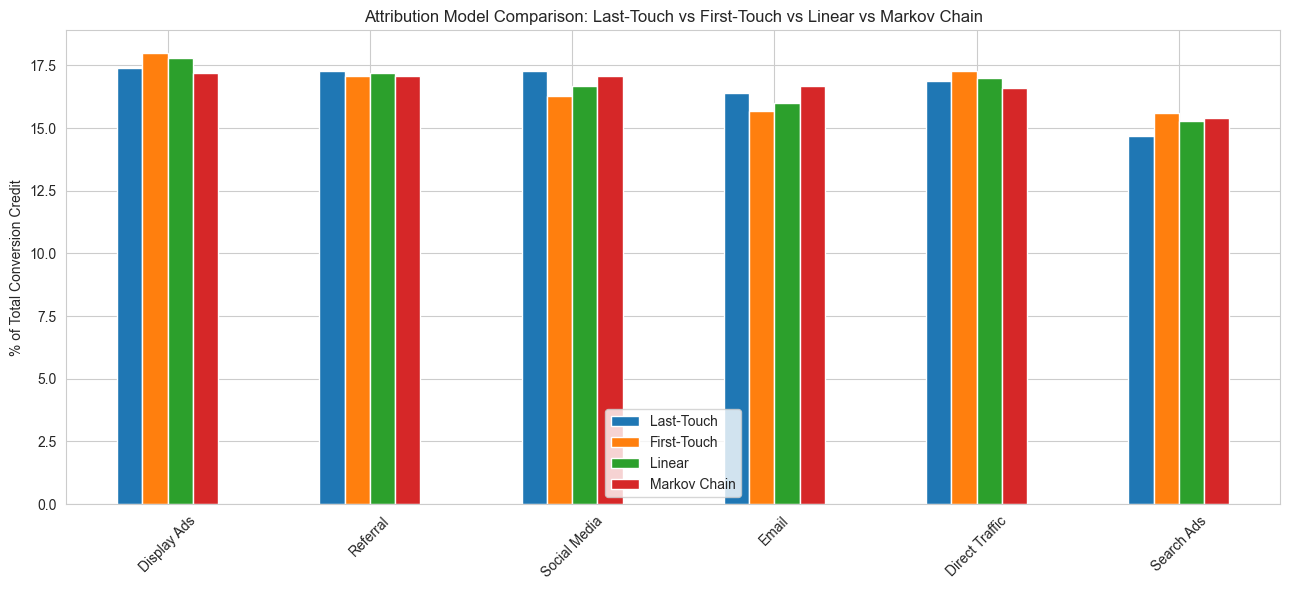


Saved to data/processed/attribution_comparison.csv


In [33]:
final_attribution = attribution_df[['last_touch_pct', 'first_touch_pct', 'linear_pct']].copy()
final_attribution['markov_pct'] = markov_series
final_attribution = final_attribution.sort_values('markov_pct', ascending=False)

print(final_attribution)

final_attribution.plot(kind='bar', figsize=(13, 6))
plt.title('Attribution Model Comparison: Last-Touch vs First-Touch vs Linear vs Markov Chain')
plt.ylabel('% of Total Conversion Credit')
plt.xticks(rotation=45)
plt.legend(['Last-Touch', 'First-Touch', 'Linear', 'Markov Chain'])
plt.tight_layout()
plt.savefig('../outputs/figures/attribution_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Save this — you'll need it for the dashboard and CAC calculations next
final_attribution.to_csv('../data/processed/attribution_comparison.csv')
print("\nSaved to data/processed/attribution_comparison.csv")

In [34]:
campaign_summary = campaign.groupby('channel_standardized').agg(
    total_spend=('spend', 'sum'),
    naive_conversions=('conversions', 'sum')
)

campaign_summary['cac_naive'] = campaign_summary['total_spend'] / campaign_summary['naive_conversions']

# Adjustment factor: how much more/less credit Markov gives vs last-touch (ratio, scale-independent)
adj_factor = final_attribution['markov_pct'] / final_attribution['last_touch_pct']
campaign_summary['markov_adjustment_factor'] = adj_factor

campaign_summary['markov_adjusted_conversions'] = (
    campaign_summary['naive_conversions'] * campaign_summary['markov_adjustment_factor']
)
campaign_summary['cac_markov_adjusted'] = (
    campaign_summary['total_spend'] / campaign_summary['markov_adjusted_conversions']
)
campaign_summary['cac_pct_change'] = (
    (campaign_summary['cac_markov_adjusted'] - campaign_summary['cac_naive'])
    / campaign_summary['cac_naive'] * 100
).round(1)

print(campaign_summary[['total_spend','naive_conversions','cac_naive',
                        'markov_adjustment_factor','cac_markov_adjusted','cac_pct_change']].round(2))

print("\nNote: 'Referral' has no paid spend in the campaign dataset (organic channel,")
print("no ad budget) - so CAC doesn't apply to it. Not an error.")

                      total_spend  naive_conversions  cac_naive  \
channel_standardized                                              
Direct Traffic        416593500.0            1477660     281.93   
Display Ads           416778582.0            1463649     284.75   
Email                 420874104.0            1485425     283.34   
Search Ads            418912314.0            1468717     285.22   
Social Media          827720108.0            2909276     284.51   

                      markov_adjustment_factor  cac_markov_adjusted  \
channel_standardized                                                  
Direct Traffic                            0.98               287.02   
Display Ads                               0.99               288.06   
Email                                     1.02               278.25   
Search Ads                                1.05               272.26   
Social Media                              0.99               287.84   

                      cac_pct_ch

                      cac_naive  cac_markov_adjusted      ltv  cac_ltv_ratio  \
channel_standardized                                                           
Direct Traffic           281.93               287.02  1694.67           0.17   
Display Ads              284.75               288.06  1708.81           0.17   
Email                    283.34               278.25  1699.61           0.16   
Search Ads               285.22               272.26  1713.55           0.16   
Social Media             284.51               287.84  1708.89           0.17   

                     risk_flag  
channel_standardized            
Direct Traffic         Healthy  
Display Ads            Healthy  
Email                  Healthy  
Search Ads             Healthy  
Social Media           Healthy  


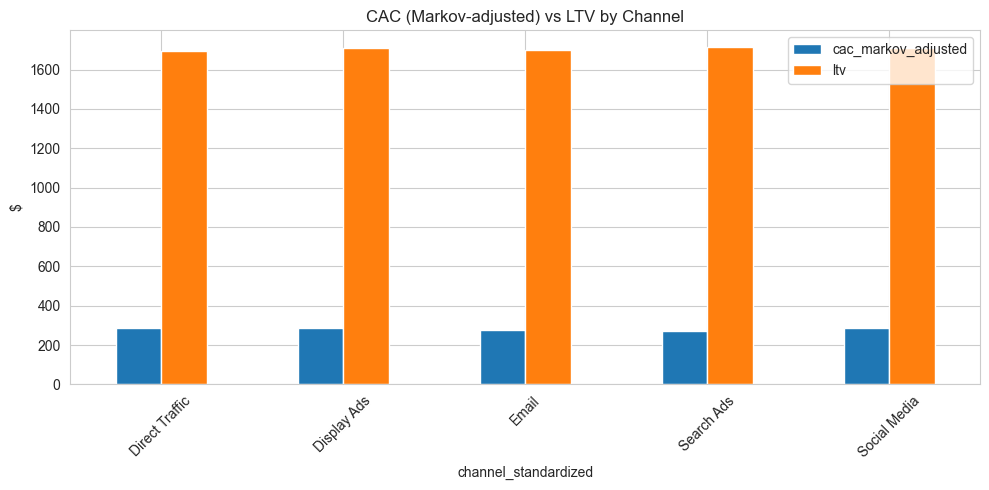


Saved to data/processed/cac_ltv_analysis.csv


In [35]:
# LTV estimate: average revenue per converted customer, per channel
ltv_by_channel = campaign.groupby('channel_standardized').agg(
    total_revenue=('revenue', 'sum'),
    total_conversions=('conversions', 'sum')
)
ltv_by_channel['ltv'] = ltv_by_channel['total_revenue'] / ltv_by_channel['total_conversions']

cac_ltv = campaign_summary[['cac_naive', 'cac_markov_adjusted']].join(ltv_by_channel['ltv'])
cac_ltv['cac_ltv_ratio'] = (cac_ltv['cac_markov_adjusted'] / cac_ltv['ltv']).round(3)

# Standard industry rule of thumb: CAC:LTV ratio should be well below 1
# (ideally under ~0.33, i.e., LTV at least 3x CAC) - values approaching or
# exceeding 1 mean you're barely breaking even or losing money per customer
cac_ltv['risk_flag'] = cac_ltv['cac_ltv_ratio'].apply(
    lambda x: 'HIGH RISK' if x >= 0.5 else ('Watch' if x >= 0.33 else 'Healthy')
)

print(cac_ltv.round(2))

cac_ltv[['cac_markov_adjusted', 'ltv']].plot(kind='bar', figsize=(10,5))
plt.title('CAC (Markov-adjusted) vs LTV by Channel')
plt.ylabel('$')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

cac_ltv.to_csv('../data/processed/cac_ltv_analysis.csv')
print("\nSaved to data/processed/cac_ltv_analysis.csv")

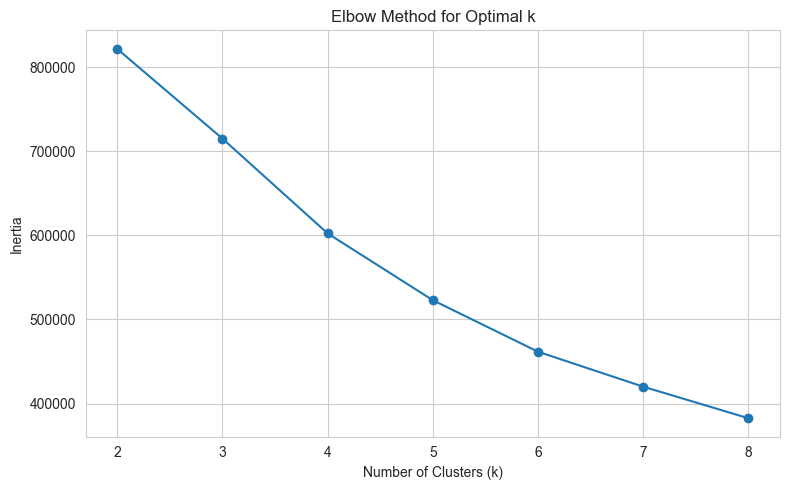

Inertia by k: {2: 821591, 3: 714976, 4: 602266, 5: 522834, 6: 461593, 7: 420051, 8: 382519}


In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select numeric behavioral features for clustering
features = ['conversion_rate', 'roi', 'ctr', 'engagement_score', 'cac']
cluster_data = campaign[features].copy()

# Scale features - K-Means is distance-based, so features on different scales
# (e.g., roi ~2-8 vs cac ~200-400) would unfairly dominate without this
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_data)

# Elbow method: try different cluster counts, see where adding more clusters
# stops meaningfully reducing "error" (inertia)
inertias = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(scaled_features)
    inertias.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(k_range, inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.tight_layout()
plt.savefig('../outputs/figures/kmeans_elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()

print("Inertia by k:", dict(zip(k_range, [round(i) for i in inertias])))

         conversion_rate   roi   ctr  engagement_score      cac  num_campaigns
segment                                                                       
0                   0.02  5.02  0.07              5.50  3007.69          17133
1                   0.09  5.00  0.11              2.96   431.25          81429
2                   0.09  5.00  0.11              8.04   427.99          81339
3                   0.08  5.00  0.46              5.45   326.11          20099


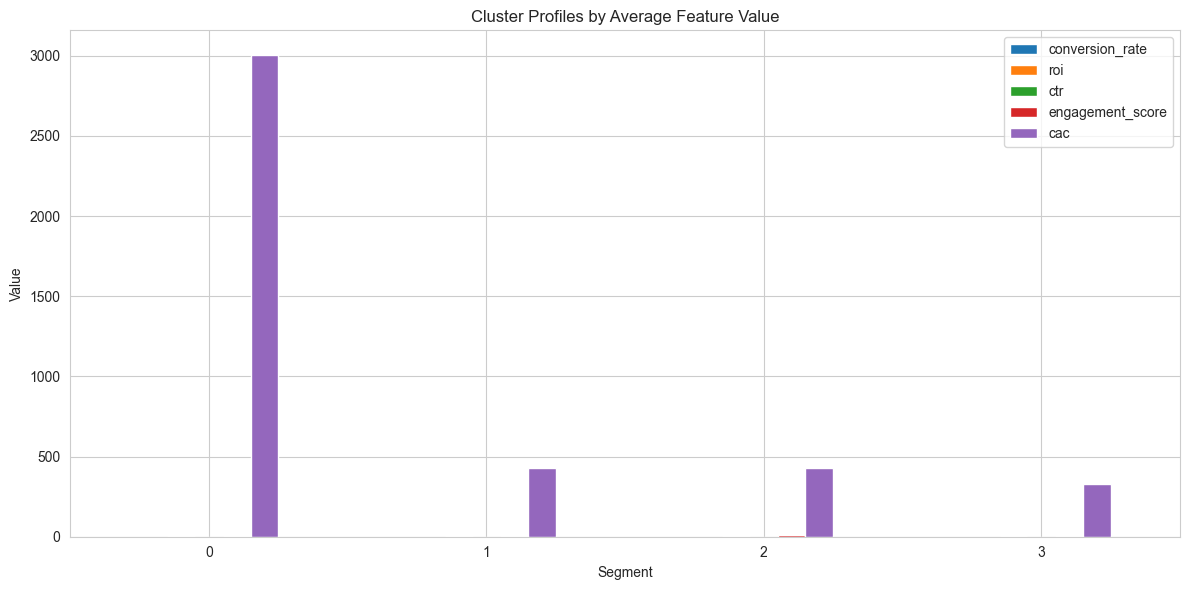


Saved to data/processed/campaign_with_segments.csv


In [37]:
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
campaign['segment'] = kmeans_final.fit_predict(scaled_features)

segment_profile = campaign.groupby('segment')[features].mean().round(2)
segment_profile['num_campaigns'] = campaign.groupby('segment').size()
print(segment_profile)

# Visualize each segment's average profile
segment_profile[features].plot(kind='bar', figsize=(12,6))
plt.title('Cluster Profiles by Average Feature Value')
plt.ylabel('Value')
plt.xlabel('Segment')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../outputs/figures/segment_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

campaign.to_csv('../data/processed/campaign_with_segments.csv', index=False)
print("\nSaved to data/processed/campaign_with_segments.csv")

In [38]:
segment_names = {
    0: 'Inefficient / High-Risk Spend',
    1: 'Efficient Converters, Low Engagement',
    2: 'High-Value Engaged Champions',
    3: 'High-CTR Efficient Spenders'
}
campaign['segment_name'] = campaign['segment'].map(segment_names)
campaign.to_csv('../data/processed/campaign_with_segments.csv', index=False)
print(campaign['segment_name'].value_counts())

segment_name
Efficient Converters, Low Engagement    81429
High-Value Engaged Champions            81339
High-CTR Efficient Spenders             20099
Inefficient / High-Risk Spend           17133
Name: count, dtype: int64


In [39]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

variant_a_name = 'Search'
variant_b_name = 'Email'

group_a = campaign[campaign['campaign_type'] == variant_a_name]
group_b = campaign[campaign['campaign_type'] == variant_b_name]

conversions_a, clicks_a = group_a['conversions'].sum(), group_a['clicks'].sum()
conversions_b, clicks_b = group_b['conversions'].sum(), group_b['clicks'].sum()

rate_a = conversions_a / clicks_a
rate_b = conversions_b / clicks_b

z_stat, p_value = proportions_ztest(
    count=[conversions_a, conversions_b],
    nobs=[clicks_a, clicks_b]
)

ci_low, ci_upp = confint_proportions_2indep(
    conversions_a, clicks_a, conversions_b, clicks_b, method='wald'
)

print(f"{variant_a_name} conversion rate: {conversions_a}/{clicks_a} = {rate_a:.4%}")
print(f"{variant_b_name} conversion rate: {conversions_b}/{clicks_b} = {rate_b:.4%}")
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"95% Confidence Interval for difference ({variant_a_name} - {variant_b_name}): [{ci_low:.4%}, {ci_upp:.4%}]")

alpha = 0.05
if p_value < alpha:
    print(f"\nResult: statistically significant difference (p < {alpha})")
else:
    print(f"\nResult: NOT statistically significant (p >= {alpha}) - observed difference could be due to chance")

Search conversion rate: 1764235/22032144 = 8.0076%
Email conversion rate: 1747009/21897902 = 7.9780%

Z-statistic: 3.6143
P-value: 0.000301
95% Confidence Interval for difference (Search - Email): [0.0135%, 0.0456%]

Result: statistically significant difference (p < 0.05)


                same_month  lag_1_month  lag_2_months
channel                                              
Direct Traffic       0.927       -0.034         0.123
Display Ads          0.874       -0.572         0.608
Email                0.860       -0.161         0.183
Search Ads           0.913       -0.306         0.214
Social Media         0.975       -0.727         0.542


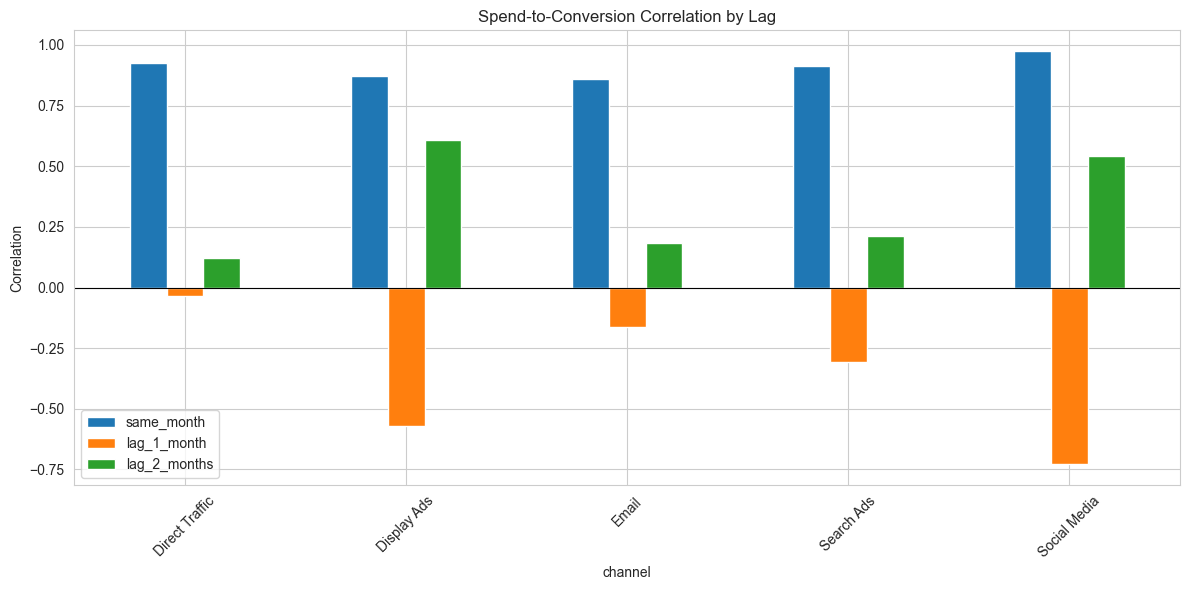

In [40]:
monthly_channel = campaign.groupby(['month', 'channel_standardized']).agg(
    spend=('spend', 'sum'),
    conversions=('conversions', 'sum')
).reset_index()

lag_results = []

for channel in monthly_channel['channel_standardized'].unique():
    ch_data = monthly_channel[monthly_channel['channel_standardized'] == channel].sort_values('month')
    spend_series = ch_data['spend'].reset_index(drop=True)
    conv_series = ch_data['conversions'].reset_index(drop=True)
    
    for lag in [0, 1, 2]:
        if lag == 0:
            corr = spend_series.corr(conv_series)
        else:
            corr = spend_series[:-lag].reset_index(drop=True).corr(conv_series[lag:].reset_index(drop=True))
        lag_results.append({'channel': channel, 'lag_months': lag, 'correlation': round(corr, 3)})

lag_df = pd.DataFrame(lag_results)
lag_pivot = lag_df.pivot(index='channel', columns='lag_months', values='correlation')
lag_pivot.columns = ['same_month', 'lag_1_month', 'lag_2_months']
print(lag_pivot)

lag_pivot.plot(kind='bar', figsize=(12,6))
plt.title('Spend-to-Conversion Correlation by Lag')
plt.ylabel('Correlation')
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
channel_roi = campaign.groupby('channel_standardized').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    avg_roi=('roi', 'mean')
).round(2).sort_values('avg_roi', ascending=False)

print("Current channel performance:\n", channel_roi)

best_channel = channel_roi.index[0]
worst_channel = channel_roi.index[-1]
print(f"\nHighest ROI channel: {best_channel} (ROI: {channel_roi.loc[best_channel,'avg_roi']})")
print(f"Lowest ROI channel: {worst_channel} (ROI: {channel_roi.loc[worst_channel,'avg_roi']})")

def simulate_reallocation(shift_pct):
    shift_amount = channel_roi.loc[worst_channel, 'total_spend'] * (shift_pct / 100)
    
    old_worst_spend = channel_roi.loc[worst_channel, 'total_spend']
    old_best_spend = channel_roi.loc[best_channel, 'total_spend']
    new_worst_spend = old_worst_spend - shift_amount
    new_best_spend = old_best_spend + shift_amount
    
    roi_worst = channel_roi.loc[worst_channel, 'avg_roi']
    roi_best = channel_roi.loc[best_channel, 'avg_roi']
    
    # BOTH old and new use the same formula now - apples to apples
    old_combined_revenue = old_worst_spend * (1 + roi_worst) + old_best_spend * (1 + roi_best)
    new_combined_revenue = new_worst_spend * (1 + roi_worst) + new_best_spend * (1 + roi_best)
    
    revenue_lift = new_combined_revenue - old_combined_revenue
    revenue_lift_pct = (revenue_lift / old_combined_revenue) * 100
    
    return {
        'shift_pct': shift_pct,
        'shift_amount': round(shift_amount, 2),
        'projected_revenue_lift': round(revenue_lift, 2),
        'projected_revenue_lift_pct': round(revenue_lift_pct, 4)
    }

simulation_results = pd.DataFrame([simulate_reallocation(p) for p in [10, 20, 30, 50]])
print("Budget Reallocation Simulation (shifting spend from",
      worst_channel, "to", best_channel, "):")
print(simulation_results)

print("\n** ESTIMATE ONLY - assumes ROI stays constant at current levels as spend shifts,")
print("which may not hold in reality (diminishing returns at higher spend levels). **")

Current channel performance:
                       total_spend  total_revenue  avg_roi
channel_standardized                                     
Direct Traffic        416593500.0   2.504152e+09     5.01
Email                 420874104.0   2.524644e+09     5.00
Search Ads            418912314.0   2.516724e+09     5.00
Social Media          827720108.0   4.971642e+09     5.00
Display Ads           416778582.0   2.501105e+09     4.99

Highest ROI channel: Direct Traffic (ROI: 5.01)
Lowest ROI channel: Display Ads (ROI: 4.99)
Budget Reallocation Simulation (shifting spend from Display Ads to Direct Traffic ):
   shift_pct  shift_amount  projected_revenue_lift  projected_revenue_lift_pct
0         10    41677858.2               833557.16                      0.0167
1         20    83355716.4              1667114.33                      0.0333
2         30   125033574.6              2500671.49                      0.0500
3         50   208389291.0              4167785.82                    

In [42]:
from scipy.stats import chi2_contingency
import numpy as np

# Rebuild converted journeys + raw counts (same logic as the original attribution cell)
converted_journeys = journeys[journeys['converted'] == 1].copy()

from collections import defaultdict
last_touch_counts = defaultdict(int)
first_touch_counts = defaultdict(int)

for path in converted_journeys['path']:
    last_touch_counts[path[-1]] += 1
    first_touch_counts[path[0]] += 1

channels = sorted(set(last_touch_counts) | set(first_touch_counts))
contingency_table = np.array([
    [last_touch_counts[ch] for ch in channels],
    [first_touch_counts[ch] for ch in channels]
])

print("Channels:", channels)
print("Contingency table (rows: Last-Touch, First-Touch):")
print(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"\nChi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print(f"\nResult: Last-Touch and First-Touch credit distributions ARE significantly different (p < {alpha})")
else:
    print(f"\nResult: NO significant difference between Last-Touch and First-Touch distributions (p >= {alpha})")
    print("This would statistically confirm what we already observed visually: attribution")
    print("model choice barely changes channel credit in this dataset.")

Channels: ['Direct Traffic', 'Display Ads', 'Email', 'Referral', 'Search Ads', 'Social Media']
Contingency table (rows: Last-Touch, First-Touch):
[[402 415 391 412 349 412]
 [411 428 374 408 371 389]]

Chi-square statistic: 2.0300
Degrees of freedom: 5
P-value: 0.8450

Result: NO significant difference between Last-Touch and First-Touch distributions (p >= 0.05)
This would statistically confirm what we already observed visually: attribution
model choice barely changes channel credit in this dataset.
